In [7]:
import pandas as pd
import numpy as numpy
import matplotlib.pyplot as plt 
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay,
    classification_report, roc_auc_score, roc_curve
)
import warnings
warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', None)
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette('husl')

In [8]:
df1 = pd.read_csv(r"C:\Users\rajni\OneDrive\Desktop\ml projects\projects\Loan_default.csv")


In [9]:
print("DATASET OVERVIEW")
print("Total Rows:", df1.shape[0])
print("Total Columns:", df1.shape[1])
print("-"*40)

print("DUPLICATE RECORDS")
print("Total Duplicate Records:", df1.duplicated().sum())
print("-"*40)

quality_report = pd.DataFrame({
    "Data Type": df1.dtypes,
    "Missing Values": df1.isnull().sum()})
display(quality_report)

print("\nCOMPLETE DATASET INFO")
# print("-------------------------")
df1.info()


DATASET OVERVIEW
Total Rows: 255347
Total Columns: 18
----------------------------------------
DUPLICATE RECORDS
Total Duplicate Records: 0
----------------------------------------


,Data Type,Missing Values
LoanID,str,0
Age,int64,0
Income,int64,0
LoanAmount,int64,0
CreditScore,int64,0
MonthsEmployed,int64,0
NumCreditLines,int64,0
InterestRate,float64,0
LoanTerm,int64,0
DTIRatio,float64,0



COMPLETE DATASET INFO
<class 'pandas.DataFrame'>
RangeIndex: 255347 entries, 0 to 255346
Data columns (total 18 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   LoanID          255347 non-null  str    
 1   Age             255347 non-null  int64  
 2   Income          255347 non-null  int64  
 3   LoanAmount      255347 non-null  int64  
 4   CreditScore     255347 non-null  int64  
 5   MonthsEmployed  255347 non-null  int64  
 6   NumCreditLines  255347 non-null  int64  
 7   InterestRate    255347 non-null  float64
 8   LoanTerm        255347 non-null  int64  
 9   DTIRatio        255347 non-null  float64
 10  Education       255347 non-null  str    
 11  EmploymentType  255347 non-null  str    
 12  MaritalStatus   255347 non-null  str    
 13  HasMortgage     255347 non-null  str    
 14  HasDependents   255347 non-null  str    
 15  LoanPurpose     255347 non-null  str    
 16  HasCoSigner     255347 non-null  str    
 17

<Axes: xlabel='Default'>

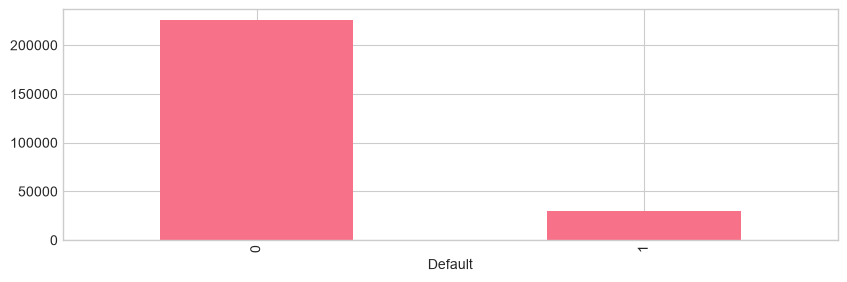

In [10]:
df1['Default'].value_counts().plot(kind='bar', figsize=(10,3))

In [11]:
num_cols = ['Age', 'Income', 'LoanAmount', 'CreditScore', 'MonthsEmployed',
       'NumCreditLines', 'InterestRate', 'LoanTerm', 'DTIRatio']

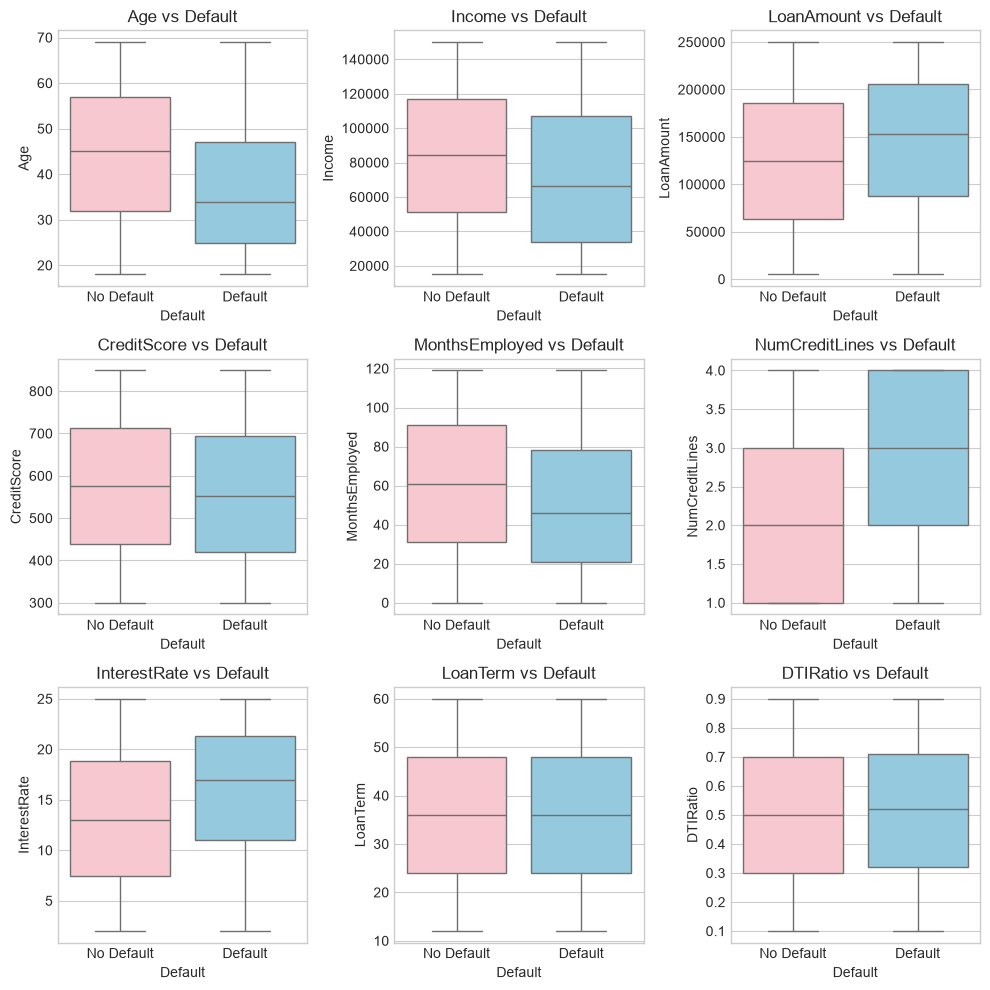

In [12]:
fig, axs = plt.subplots(3,3, figsize = (10,10))
axs = axs.flatten()
for index, column_name in enumerate(num_cols):
    sns.boxplot(data = df1, y = column_name, x = 'Default', ax=axs[index], palette=  ['pink', 'skyblue'])
    axs[index].set_title(f'{column_name} vs Default')
    axs[index].set_xticklabels(['No Default', 'Default'])
    plt.tight_layout()


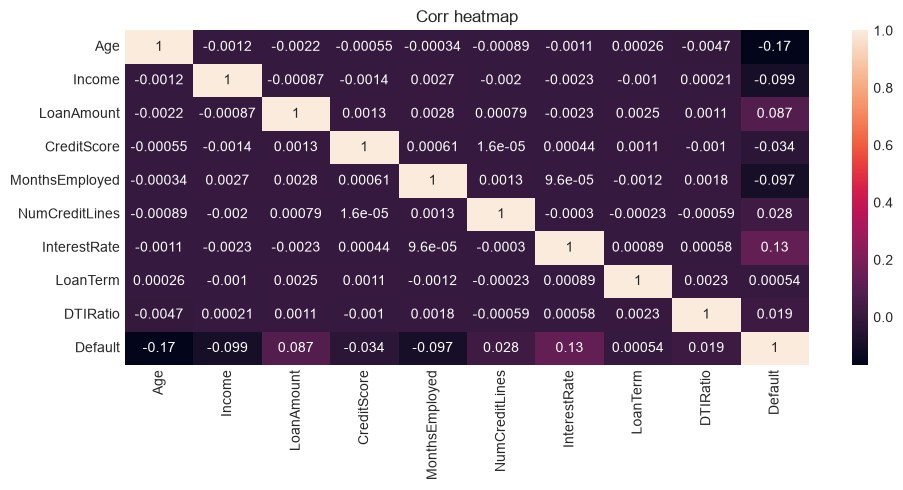

In [13]:
#correlation matrix

plt.figure(figsize=(10,5))
sns.heatmap(df1[num_cols + ['Default']].corr(), annot=True)
plt.title('Corr heatmap')
plt.tight_layout()
plt.show()

In [14]:
#data preprocessing

df1.drop('LoanID', axis = 1, inplace = True)


In [15]:
X = df1.drop('Default', axis =1)
y = df1['Default']

In [16]:
cat_cols = X.select_dtypes(include = 'str').columns.to_list()
label_encoders = {}

for col in cat_cols:
    le = LabelEncoder()
    X[col]=le.fit_transform(X[col].astype(str))
    print(f'encoded {col}: {dict(zip(le.classes_, le.transform(le.classes_)))}')

encoded Education: {"Bachelor's": np.int64(0), 'High School': np.int64(1), "Master's": np.int64(2), 'PhD': np.int64(3)}
encoded EmploymentType: {'Full-time': np.int64(0), 'Part-time': np.int64(1), 'Self-employed': np.int64(2), 'Unemployed': np.int64(3)}
encoded MaritalStatus: {'Divorced': np.int64(0), 'Married': np.int64(1), 'Single': np.int64(2)}
encoded HasMortgage: {'No': np.int64(0), 'Yes': np.int64(1)}
encoded HasDependents: {'No': np.int64(0), 'Yes': np.int64(1)}
encoded LoanPurpose: {'Auto': np.int64(0), 'Business': np.int64(1), 'Education': np.int64(2), 'Home': np.int64(3), 'Other': np.int64(4)}
encoded HasCoSigner: {'No': np.int64(0), 'Yes': np.int64(1)}


In [17]:
x_train, x_test, y_train, y_test= train_test_split(
X, y, test_size = 0.2, random_state = 22)

scaler = StandardScaler()
x_train_scaled = x_train.copy()
x_test_scaled = x_test.copy()
x_train_scaled[num_cols] = scaler.fit_transform(x_train[num_cols])
x_test_scaled[num_cols] = scaler.fit_transform(x_test[num_cols])

In [18]:
lr = LogisticRegression(class_weight= 'balanced', max_iter=200,
solver='lbfgs')
lr.fit(x_train_scaled,y_train)
y_pred=lr.predict(x_test_scaled)
y_pred_proba = lr.predict(x_test_scaled)

In [19]:
print(f'accuracy score: {accuracy_score(y_test,y_pred)}')
print(f'precision score: {precision_score(y_test,y_pred)}')
print(f'recall score: {recall_score(y_test,y_pred)}')
print(f'roc auc score: {roc_auc_score(y_test,y_pred)}')
print(f'f1 score: {f1_score(y_test,y_pred)}')

accuracy score: 0.6735656941452908
precision score: 0.2170673712021136
recall score: 0.6890305266689031
roc auc score: 0.6802761039835603
f1 score: 0.33013219753284845


In [20]:
print(classification_report(y_test, y_pred,
target_names=['No Default', 'default']))

              precision    recall  f1-score   support

  No Default       0.94      0.67      0.78     45108
     default       0.22      0.69      0.33      5962

    accuracy                           0.67     51070
   macro avg       0.58      0.68      0.56     51070
weighted avg       0.86      0.67      0.73     51070



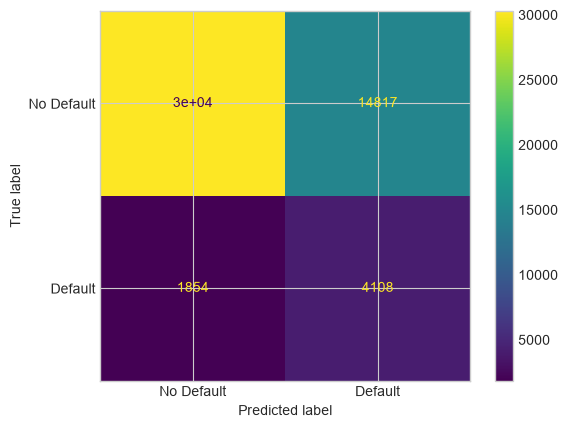

In [21]:
cm = confusion_matrix(y_test, y_pred)
dis = ConfusionMatrixDisplay(confusion_matrix=cm,
display_labels=['No Default', 'Default'])
dis.plot()
plt.show()

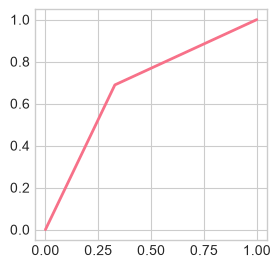

In [22]:
fpr, tpr, threshold = roc_curve(y_test, y_pred_proba)
plt.figure(figsize=(3,3))
plt.plot(fpr, tpr, lw=2)

In [23]:
coef_df = pd.DataFrame({
'columns': x_train.columns,
'coefficient':lr.coef_[0]}).sort_values(by = 'coefficient', key=abs, ascending=False)

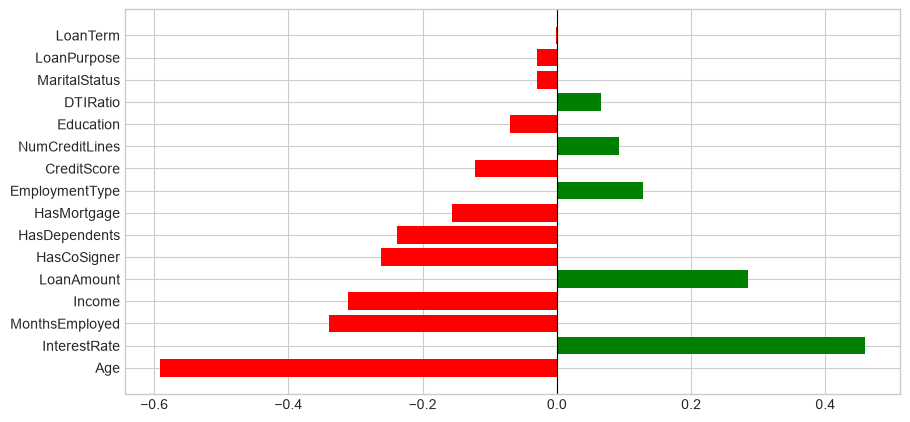

In [24]:
plt.figure(figsize=(10,5))
color = ['g' if c>0 else 'r' for c in coef_df['coefficient']]
plt.barh(coef_df['columns'], coef_df['coefficient'], color=color)
plt.axvline(x=0, color = 'black', linewidth = 0.8, linestyle = '-')
plt.show()

In [25]:
import joblib
joblib.dump(lr,'Logistic_regression.pkl')

['Logistic_regression.pkl']

In [26]:
model = joblib.load('Logistic_regression.pkl')
model.predict(x_test.iloc[:2,:])

array([1, 1])